Dataset diambil dari Kaggle

In [ ]:
import kagglehub
import shutil
import os
import pandas as pd

# Download dataset dari Kaggle
# (Catatan: Pastikan path ini benar. Format standar Kaggle biasanya "username/nama-dataset")
dataset_path = kagglehub.dataset_download(
    "leonss0711/cleaned-indonesian-cyberbullying-dataset"
)

print("Dataset downloaded to:", dataset_path)

# Nama file yang mau dipakai diubah menjadi .csv
source_file = os.path.join(dataset_path, "combined_dataset.csv")
source_file2 = os.path.join(dataset_path, "kamus_singkatan.csv")

# Pindahkan ke Files Colab (/content)
destination_file = "/content/combined_dataset.csv"
destination_file2 = "/content/kamus_singkatan.csv"

shutil.copy(source_file, destination_file)
shutil.copy(source_file2, destination_file2)

print("File copied to:", destination_file)
print("File copied to:", destination_file2)

# Load CSV (parameter sep="\t" dihapus karena file sekarang dipisahkan dengan koma)
df_combined = pd.read_csv(destination_file)
df_kamus = pd.read_csv(destination_file2)

print("\nFirst 5 records of Combined Dataset:")
print(df_combined.head())

print("\nFirst 5 records of Kamus Singkatan:")
print(df_kamus.head())

Using Colab cache for faster access to the 'cleaned-indonesian-cyberbullying-dataset' dataset.
Dataset downloaded to: /kaggle/input/cleaned-indonesian-cyberbullying-dataset
File copied to: /content/combined_dataset.csv
File copied to: /content/kamus_singkatan.csv

First 5 records of Combined Dataset:
   Unnamed: 0         Label  \
0           0  Non-bullying   
1           1  Non-bullying   
2           2      Bullying   
3           3  Non-bullying   
4           4  Non-bullying   

                                          clean_text  \
0       kaka tidur yaa sudah pagi tidak boleh capek2   
1                    makan nasi padang saja badannya   
2                         suka cukur jembut manggung   
3  hai kak isyana ngefans sekali kak isyana suka ...   
4             manusia bidadari sih herann deh cantik   

                                              String  encoded_label  
0        "Kaka tidur yaa, udah pagi, gaboleh capek2"            1.0  
1            "makan nasi padang aj

In [ ]:
print(f"Total data points in the dataset: {len(df_combined)}")

Total data points in the dataset: 2066


In [ ]:
df = pd.read_csv(destination_file, sep="\t")

print("\nFirst 5 records:")
print(df.head())


First 5 records:
              ,Label,clean_text,String,encoded_label
0  0,Non-bullying,kaka tidur yaa sudah pagi tidak...
1  1,Non-bullying,makan nasi padang saja badannya...
2  2,Bullying,suka cukur jembut manggung,"""yang ...
3  3,Non-bullying,hai kak isyana ngefans sekali k...
4  4,Non-bullying,manusia bidadari sih herann deh...


In [ ]:
print("\n--- Normalizing abbreviations in combined_dataset ---")

# Create a dictionary for abbreviation mapping from df_kamus
abbreviation_map = dict(zip(df_kamus['singkatan'], df_kamus['asli']))

def normalize_abbreviations(text, abbr_map):
    if not isinstance(text, str): # Handle non-string types, e.g., NaNs
        return text
    # Split text into words, replace abbreviations, then join back
    words = text.split()
    normalized_words = [abbr_map.get(word.lower(), word) for word in words]
    return ' '.join(normalized_words)

# Apply the normalization function to the 'clean_text' column
df_combined['clean_text_normalized'] = df_combined['clean_text'].apply(lambda x: normalize_abbreviations(x, abbreviation_map))

print("First 5 records of Combined Dataset with normalized text:")
print(df_combined[['clean_text', 'clean_text_normalized']].head())

print("Abbreviation normalization complete.")


--- Normalizing abbreviations in combined_dataset ---
First 5 records of Combined Dataset with normalized text:
                                          clean_text  \
0       kaka tidur yaa sudah pagi tidak boleh capek2   
1                    makan nasi padang saja badannya   
2                         suka cukur jembut manggung   
3  hai kak isyana ngefans sekali kak isyana suka ...   
4             manusia bidadari sih herann deh cantik   

                               clean_text_normalized  
0       kaka tidur yaa sudah pagi tidak boleh capek2  
1                    makan nasi padang saja badannya  
2                         suka cukur jembut manggung  
3  hai kak isyana ngefans sekali kak isyana suka ...  
4             manusia bidadari sih herann deh cantik  
Abbreviation normalization complete.


In [ ]:
df_combined.columns

Index(['Unnamed: 0', 'Label', 'clean_text', 'String', 'encoded_label',
       'clean_text_normalized'],
      dtype='object')

In [ ]:
print("\n--- Dropping 'Unnamed: 0' column ---")

if 'Unnamed: 0' in df_combined.columns:
    df_combined.drop(columns=['Unnamed: 0'], inplace=True)
    print("Column 'Unnamed: 0' dropped successfully.")
else:
    print("Column 'Unnamed: 0' not found in df_combined.")

print("Updated columns in df_combined:")
print(df_combined.columns)
print("First 5 records of df_combined after dropping 'Unnamed: 0':")
print(df_combined.head())


--- Dropping 'Unnamed: 0' column ---
Column 'Unnamed: 0' dropped successfully.
Updated columns in df_combined:
Index(['Label', 'clean_text', 'String', 'encoded_label',
       'clean_text_normalized'],
      dtype='object')
First 5 records of df_combined after dropping 'Unnamed: 0':
          Label                                         clean_text  \
0  Non-bullying       kaka tidur yaa sudah pagi tidak boleh capek2   
1  Non-bullying                    makan nasi padang saja badannya   
2      Bullying                         suka cukur jembut manggung   
3  Non-bullying  hai kak isyana ngefans sekali kak isyana suka ...   
4  Non-bullying             manusia bidadari sih herann deh cantik   

                                              String  encoded_label  \
0        "Kaka tidur yaa, udah pagi, gaboleh capek2"            1.0   
1            "makan nasi padang aja begini badannya"            1.0   
2  "yang aku suka dari dia adalah selalu cukur je...            0.0   
3  "Hai kak

In [ ]:
print("\n--- Preprocessing: Removing Duplicates and Null Values ---")

print("Original shape of df_combined:", df_combined.shape)
print("Number of duplicate rows before removal:", df_combined.duplicated().sum())
print("Number of null values per column before removal:")
print(df_combined.isnull().sum())

# Remove duplicate rows
df_combined.drop_duplicates(inplace=True)
print("Shape of df_combined after removing duplicates:", df_combined.shape)

# Remove rows with any null values
df_combined.dropna(inplace=True)
print("Shape of df_combined after removing null values:", df_combined.shape)

print("Number of null values per column after removal:")
print(df_combined.isnull().sum())

print("Data cleaning (duplicates and nulls) complete.")
print("First 5 records of cleaned df_combined:")
print(df_combined.head())


--- Preprocessing: Removing Duplicates and Null Values ---
Original shape of df_combined: (2066, 5)
Number of duplicate rows before removal: 0
Number of null values per column before removal:
Label                    0
clean_text               0
String                   0
encoded_label            0
clean_text_normalized    0
dtype: int64
Shape of df_combined after removing duplicates: (2066, 5)
Shape of df_combined after removing null values: (2066, 5)
Number of null values per column after removal:
Label                    0
clean_text               0
String                   0
encoded_label            0
clean_text_normalized    0
dtype: int64
Data cleaning (duplicates and nulls) complete.
First 5 records of cleaned df_combined:
          Label                                         clean_text  \
0  Non-bullying       kaka tidur yaa sudah pagi tidak boleh capek2   
1  Non-bullying                    makan nasi padang saja badannya   
2      Bullying                         suka cuku

In [ ]:
print("Unique labels in 'Label' column:")
print(df_combined['Label'].unique())

Unique labels in 'Label' column:
['Non-bullying' 'Bullying' 'positif' 'negatif' 'negative' 'positive']


In [ ]:
print("\n--- Data Summary ---")
print(f"Total data points: {len(df_combined)}")

# Count the occurrences of each sentiment label
sentiment_counts = df_combined['Label'].value_counts()

print("Sentiment distribution:")
print(sentiment_counts)


--- Data Summary ---
Total data points: 2066
Sentiment distribution:
Label
negatif         614
positif         405
Bullying        325
Non-bullying    325
positive        200
negative        197
Name: count, dtype: int64


In [ ]:
print("\n--- Standardizing Sentiment Labels ---")

# Create a mapping for the labels
label_standardization_map = {
    'positif': 'non_bullying',
    'Non-bullying': 'non_bullying',
    'positive': 'non_bullying',
    'negatif': 'bullying',
    'Bullying': 'bullying',
    'negative': 'bullying'
}

# Apply the mapping to the 'Label' column
df_combined['Label_Standardized'] = df_combined['Label'].map(label_standardization_map)

print("Original label distribution:")
print(df_combined['Label'].value_counts())

print("\nStandardized label distribution:")
print(df_combined['Label_Standardized'].value_counts())

# Optionally, replace the original 'Label' column with the standardized one
df_combined['Label'] = df_combined['Label_Standardized']

print("\nUpdated 'Label' column head:")
print(df_combined[['Label', 'clean_text_normalized']].head())

print("Sentiment label standardization complete.")


--- Standardizing Sentiment Labels ---
Original label distribution:
Label
negatif         614
positif         405
Bullying        325
Non-bullying    325
positive        200
negative        197
Name: count, dtype: int64

Standardized label distribution:
Label_Standardized
bullying        1136
non_bullying     930
Name: count, dtype: int64

Updated 'Label' column head:
          Label                              clean_text_normalized
0  non_bullying       kaka tidur yaa sudah pagi tidak boleh capek2
1  non_bullying                    makan nasi padang saja badannya
2      bullying                         suka cukur jembut manggung
3  non_bullying  hai kak isyana ngefans sekali kak isyana suka ...
4  non_bullying             manusia bidadari sih herann deh cantik
Sentiment label standardization complete.


In [ ]:
print(f"Total number of columns in the dataset: {df_combined.shape[1]}")
print("Column names:")
for col in df_combined.columns.tolist():
    print(f"- {col}")

Total number of columns in the dataset: 6
Column names:
- Label
- clean_text
- String
- encoded_label
- clean_text_normalized
- Label_Standardized


Libraries imported successfully.

--- 1. Data Preparation ---
Unique labels found in dataset: ['non_bullying' 'bullying']
Dataset shape after label mapping: (2066, 2)
Class distribution: label
1    0.549855
0    0.450145
Name: proportion, dtype: float64
Dataset splits: DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 1239
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 413
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 414
    })
})

--- 2. Defining Hyperparameters ---
Epochs: 3, Batch Size: 16, Learning Rate: 2e-05

--- 5. Running Main Experiment Loop ---

--- Starting experiment for BERT Klasik ---


Map:   0%|          | 0/1239 [00:00<?, ? examples/s]

Map:   0%|          | 0/413 [00:00<?, ? examples/s]

Map:   0%|          | 0/414 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] `loggin

... (5 outputs left out)

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Training metrics for BERT Klasik: {'train_runtime': 265.5188, 'train_samples_per_second': 13.999, 'train_steps_per_second': 0.881, 'total_flos': 244495948193280.0, 'train_loss': 0.4400115512375139, 'epoch': 3.0}
Evaluating BERT Klasik on test set...


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,Precision Macro,Recall Macro
0.317042,0.414474,3,0.821256,0.815022,0.831157,0.810979


Evaluation results for BERT Klasik: {'eval_loss': 0.4144740104675293, 'eval_accuracy': 0.821256038647343, 'eval_f1_macro': 0.8150223402970656, 'eval_precision_macro': 0.8311570912012857, 'eval_recall_macro': 0.8109790605546123}
Peak VRAM usage for BERT Klasik: 2541.84 MB


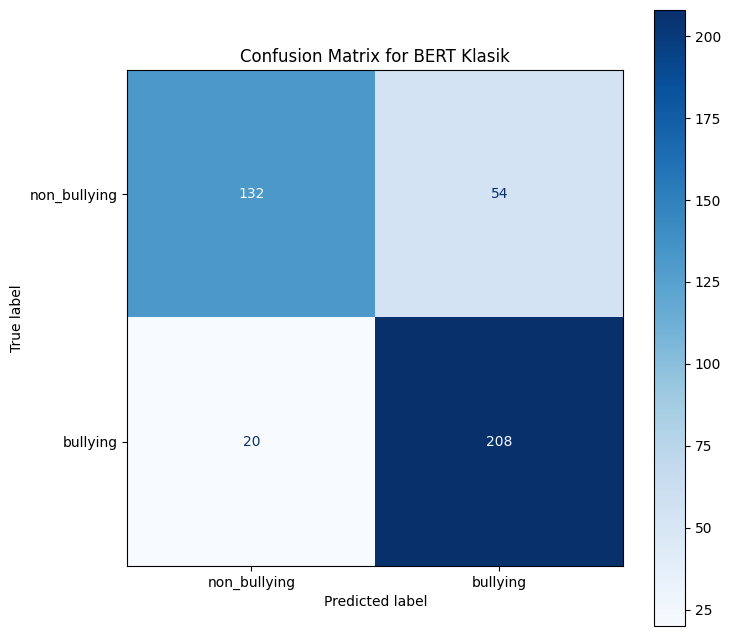

Total time for BERT Klasik: 279.16 seconds
GPU memory cleared for BERT Klasik.

--- Starting experiment for ModernBERT ---


Map:   0%|          | 0/1239 [00:00<?, ? examples/s]

Map:   0%|          | 0/413 [00:00<?, ? examples/s]

Map:   0%|          | 0/414 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.weight | MISSING    | 
classifier.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': None, 'bos_token_id': None}.


... (4 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training metrics for ModernBERT: {'train_runtime': 386.0963, 'train_samples_per_second': 9.627, 'train_steps_per_second': 0.606, 'total_flos': 316649228410368.0, 'train_loss': 0.43704977122127503, 'epoch': 3.0}
Evaluating ModernBERT on test set...


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,Precision Macro,Recall Macro
0.263008,0.400623,3,0.847826,0.844886,0.849578,0.842530


Evaluation results for ModernBERT: {'eval_loss': 0.4006229639053345, 'eval_accuracy': 0.8478260869565217, 'eval_f1_macro': 0.8448857249906332, 'eval_precision_macro': 0.8495776478232618, 'eval_recall_macro': 0.8425297113752122}
Peak VRAM usage for ModernBERT: 3934.79 MB


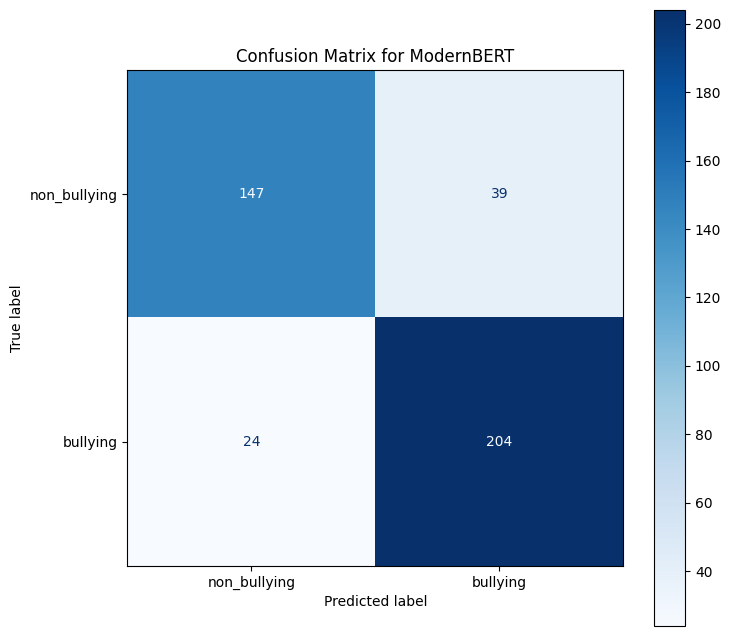

Total time for ModernBERT: 400.50 seconds
GPU memory cleared for ModernBERT.

--- 6. Recap and Save Results ---
Experiment Summary:
    model_name  accuracy  f1_macro  precision_macro  recall_macro  \
0  BERT Klasik  0.821256  0.815022         0.831157      0.810979   
1   ModernBERT  0.847826  0.844886         0.849578      0.842530   

   training_time_sec                                 predictions_object  \
0         279.163520  ([[-1.3556921, 0.58232665], [-1.513443, 1.1015...   
1         400.495067  ([[-2.7335365, 0.19804011], [-3.6112583, 2.233...   

                      id_to_label_map  peak_vram_mb  
0  {0: 'non_bullying', 1: 'bullying'}   2541.844727  
1  {0: 'non_bullying', 1: 'bullying'}   3934.790039  
Results saved to sentiment_analysis_comparison_results.csv

Cross-Lingual Transfer Learning Experiment Completed!


In [ ]:
import pandas as pd
import numpy as np
import torch
import gc
import time
import evaluate
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import Dataset, DatasetDict, Features, ClassLabel, Value
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer

print("Libraries imported successfully.")

# --- 1. Data Preparation ---
print("\n--- 1. Data Preparation ---")
# Use df_combined which has been preprocessed and correctly loaded
current_df = df_combined.copy()

# Rename columns to 'text' and 'label' as expected by Hugging Face datasets
# Using 'clean_text_normalized' as the text column since it's the processed text
current_df = current_df.rename(columns={'clean_text_normalized': 'text', 'Label': 'label'})

# Map sentiment labels to numerical IDs
# The dataset has 'Non-bullying' and 'Bullying' labels, not 'negative', 'neutral', 'positive'
label_to_id = {
    'non_bullying': 0,
    'bullying': 1
}
id_to_label = {v: k for k, v in label_to_id.items()}

unique_labels_in_df = current_df['label'].unique()
print(f"Unique labels found in dataset: {unique_labels_in_df}")

# Filter out labels that are not in our defined mapping (if any unexpected labels exist)
valid_labels_in_df = [lbl for lbl in unique_labels_in_df if lbl in label_to_id]
if not valid_labels_in_df:
    raise ValueError(f"No valid labels found in the dataset after filtering. Expected one of {list(label_to_id.keys())}, but found {unique_labels_in_df}.")

current_df = current_df[current_df['label'].isin(valid_labels_in_df)].copy()
current_df['label'] = current_df['label'].map(label_to_id).astype(int)

# Remove other columns not needed for the HF dataset, keeping only 'text' and 'label'
current_df = current_df[['text', 'label']]

# Check for label diversity and warn the user
num_unique_labels_after_mapping = len(current_df['label'].unique())
if num_unique_labels_after_mapping < 2:
    print("\n=================================================================================")
    print("WARNING: The dataset (after mapping) contains only ONE unique sentiment label.")
    print("         Multi-class sentiment analysis and stratified splitting are not meaningful or possible.")
    print("         The experiment will proceed, but results will only reflect single-class performance,")
    print("         and the confusion matrix will be trivial (1x1). For a proper multi-class analysis,")
    print("         please ensure your dataset has 'Non-bullying' and 'Bullying' labels.")
    print("=================================================================================\n")
    can_stratify = False
else:
    print(f"Dataset shape after label mapping: {current_df.shape}")
    print(f"Class distribution: {current_df['label'].value_counts(normalize=True)}")
    can_stratify = True

# Define features for Hugging Face Dataset, explicitly setting 'label' as ClassLabel
feature_dict = {
    'text': Value('string'), # Changed to Value('string') for explicit type definition
    'label': ClassLabel(names=list(label_to_id.keys())) # Define ClassLabel for 'label' column
}
hf_features = Features(feature_dict)

# Convert pandas DataFrame to Hugging Face Dataset with defined features
hf_dataset = Dataset.from_pandas(current_df.reset_index(drop=True), features=hf_features)

# Split into training, validation, and test sets
if can_stratify:
    train_val_test_split = hf_dataset.train_test_split(test_size=0.2, stratify_by_column='label', seed=42)
    test_dataset = train_val_test_split['test']
    train_val_split = train_val_test_split['train'].train_test_split(test_size=0.25, stratify_by_column='label', seed=42) # 0.25 * 0.8 = 0.2 of original
else:
    # If only one label, cannot stratify
    train_val_test_split = hf_dataset.train_test_split(test_size=0.2, seed=42)
    test_dataset = train_val_test_split['test']
    train_val_split = train_val_test_split['train'].train_test_split(test_size=0.25, seed=42) # 0.25 * 0.8 = 0.2 of original

train_dataset = train_val_split['train']
val_dataset = train_val_split['test']

dataset_dict = DatasetDict({
    'train': train_dataset,
    'validation': val_dataset,
    'test': test_dataset
})

print(f"Dataset splits: {dataset_dict}")

# --- 2. Define Hyperparameters ---
print("\n--- 2. Defining Hyperparameters ---")
epochs = 3
batch_size = 16
learning_rate = 2e-5
warmup_steps = 500
weight_decay = 0.01

print(f"Epochs: {epochs}, Batch Size: {batch_size}, Learning Rate: {learning_rate}")

# --- 3. Evaluation Metrics ---
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_metric.compute(predictions=predictions, references=labels)['accuracy']

    # Handle macro metrics gracefully if only one class is present
    if num_unique_labels_after_mapping > 1:
        f1_macro = f1_metric.compute(predictions=predictions, references=labels, average='macro')['f1']
        precision_macro = precision_metric.compute(predictions=predictions, references=labels, average='macro')['precision']
        recall_macro = recall_metric.compute(predictions=predictions, references=labels, average='macro')['recall']
    else:
        print("\nSkipping Macro F1, Precision, and Recall calculation: Only one unique label in dataset.")
        f1_macro = float('nan')
        precision_macro = float('nan')
        recall_macro = float('nan')

    return {
        "accuracy": accuracy,
        "f1_macro": f1_macro,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro
    }

# --- 4. Training and Evaluation Function with OOM Prevention ---
def train_and_evaluate_model(model_name, tokenizer_name, dataset_dict, output_dir_prefix="results"):
    print(f"\n--- Starting experiment for {model_name} ---")
    start_time = time.time()

    # Clear GPU memory before loading model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats() # Reset VRAM stats at the start of each model run
    gc.collect()

    # Tokenizer
    tokenizer = AutoTokenizer.from_pretrained(tokenizer_name)

    def tokenize_function(examples):
        return tokenizer(examples["text"], truncation=True, padding="max_length", max_length=128)

    # The remove_columns argument should only remove 'text', not 'label'
    tokenized_datasets = dataset_dict.map(tokenize_function, batched=True, remove_columns=["text"])
    tokenized_datasets.set_format("torch", columns=["input_ids", "attention_mask", "label"])

    # Model - num_labels should reflect the intended output classes (3 for sentiment analysis)
    model = AutoModelForSequenceClassification.from_pretrained(
        tokenizer_name, num_labels=len(label_to_id), id2label=id_to_label, label2id=label_to_id
    )

    # Training Arguments
    training_args = TrainingArguments(
        output_dir=f"./{output_dir_prefix}/{model_name}",
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=learning_rate,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        num_train_epochs=epochs,
        weight_decay=weight_decay,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro" if num_unique_labels_after_mapping > 1 else "accuracy",
        greater_is_better=True,
        push_to_hub=False,
        report_to="none",
        logging_dir=f"./{output_dir_prefix}/{model_name}/logs",
        logging_steps=10,
        gradient_accumulation_steps=1,
        use_cpu=not torch.cuda.is_available()
    )

    # Trainer
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_datasets["train"],
        eval_dataset=tokenized_datasets["validation"],
        compute_metrics=compute_metrics,
        processing_class=tokenizer,
    )

    # Train
    print(f"Training {model_name}...")
    train_result = trainer.train()
    train_metrics = train_result.metrics
    print(f"Training metrics for {model_name}: {train_metrics}")

    # Evaluate on test set
    print(f"Evaluating {model_name} on test set...")
    eval_results = trainer.evaluate(tokenized_datasets["test"])
    print(f"Evaluation results for {model_name}: {eval_results}")

    # Get peak VRAM usage
    peak_vram_mb = float('nan')
    if torch.cuda.is_available():
        peak_vram_mb = torch.cuda.max_memory_allocated() / (1024 ** 2) # Convert bytes to MB
        print(f"Peak VRAM usage for {model_name}: {peak_vram_mb:.2f} MB")

    # Predictions for Confusion Matrix
    predictions = trainer.predict(tokenized_datasets["test"])
    preds = np.argmax(predictions.predictions, axis=-1)
    labels = predictions.label_ids

    # Confusion Matrix
    if num_unique_labels_after_mapping > 1:
        # Ensure labels for Confusion Matrix are correctly ordered and cover all possible classes (0, 1)
        unique_actual_labels = sorted(list(np.unique(labels)))
        cm_display_labels = [id_to_label[i] for i in unique_actual_labels]

        cm = confusion_matrix(labels, preds, labels=unique_actual_labels)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cm_display_labels)
        fig, ax = plt.subplots(figsize=(8, 8))
        disp.plot(cmap=plt.cm.Blues, ax=ax)
        ax.set_title(f"Confusion Matrix for {model_name}")
        plt.show()
        plt.close(fig)
    else:
        print(f"Skipping Confusion Matrix for {model_name}: Only one unique label in dataset, cannot create meaningful matrix.")

    end_time = time.time()
    total_training_time = end_time - start_time
    print(f"Total time for {model_name}: {total_training_time:.2f} seconds")

    # Clean up memory after model is no longer needed
    del model
    del trainer
    del tokenizer
    del tokenized_datasets
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()
    print(f"GPU memory cleared for {model_name}.")

    return {
        "model_name": model_name,
        "accuracy": eval_results["eval_accuracy"],
        "f1_macro": eval_results.get("eval_f1_macro", float('nan')),
        "precision_macro": eval_results.get("eval_precision_macro", float('nan')),
        "recall_macro": eval_results.get("eval_recall_macro", float('nan')),
        "training_time_sec": total_training_time,
        "predictions_object": predictions,
        "id_to_label_map": id_to_label,
        "peak_vram_mb": peak_vram_mb # Include peak VRAM in the returned dictionary
    }

# --- 5. Main Experiment Loop ---
print("\n--- 5. Running Main Experiment Loop ---")
experiment_results = []

# Model 1: bert-base-uncased (BERT Klasik)
bert_classic_results = train_and_evaluate_model(
    model_name="BERT Klasik",
    tokenizer_name="bert-base-uncased",
    dataset_dict=dataset_dict,
    output_dir_prefix="bert_classic_results"
)
experiment_results.append(bert_classic_results)

# Model 2: answerdotai/ModernBERT-base (ModernBERT)
modern_bert_results = train_and_evaluate_model(
    model_name="ModernBERT",
    tokenizer_name="answerdotai/ModernBERT-base",
    dataset_dict=dataset_dict,
    output_dir_prefix="modern_bert_results"
)
experiment_results.append(modern_bert_results)

# Store ModernBERT predictions and label map globally for cell Oph0_dFKDPiQ
global modern_bert_predictions_obj, id_to_label_global
modern_bert_predictions_obj = modern_bert_results["predictions_object"]
id_to_label_global = modern_bert_results["id_to_label_map"]

# --- 6. Recap and Save Results ---
print("\n--- 6. Recap and Save Results ---")
results_df = pd.DataFrame(experiment_results)
print("Experiment Summary:")
print(results_df)

# Save to CSV
output_csv_path = "sentiment_analysis_comparison_results.csv"
results_df.to_csv(output_csv_path, index=False)
print(f"Results saved to {output_csv_path}")

print("\nCross-Lingual Transfer Learning Experiment Completed!")

In [ ]:
print("\n--- Performance Metrics ---")

# Create a list to store extracted metrics
performance_data = []

for result in experiment_results:
    model_name = result['model_name']
    train_runtime = result['training_time_sec']

    # Extract inference runtime and samples/sec from predictions_object.metrics
    predictions_metrics = result['predictions_object'].metrics
    inference_runtime = predictions_metrics.get('test_runtime', float('nan'))
    samples_per_sec = predictions_metrics.get('test_samples_per_second', float('nan'))

    # Extract Peak VRAM metric, which is now included in the result dictionary
    peak_vram = result.get('peak_vram_mb', float('nan'))

    performance_data.append({
        'Model': model_name,
        'Train Runtime (s)': f'{train_runtime:.2f}',
        'Inference Runtime (s)': f'{inference_runtime:.2f}',
        'Samples/sec': f'{samples_per_sec:.2f}',
        'Peak VRAM (MB)': f'{peak_vram:.2f}'
    })

performance_df = pd.DataFrame(performance_data)
print(performance_df.to_string(index=False))


--- Performance Metrics ---
      Model Train Runtime (s) Inference Runtime (s) Samples/sec Peak VRAM (MB)
BERT Klasik            279.16                  3.36      123.06        2541.84
 ModernBERT            400.50                  4.72       87.74        3934.79
